In [1]:
import pandas as pd
import matplotlib.pyplot as plt

trials = pd.read_csv("../data/processed/trials.csv")
trials.shape

(8282, 17)

In [2]:
trials["searched_conditions"].str.split("; ").explode().value_counts()

searched_conditions
stroke                           2674
depression                       1469
chronic pain                     1250
obstructive sleep apnea           919
Parkinson disease                 866
spinal cord injury                758
epilepsy                          298
migraine                          238
amyotrophic lateral sclerosis     135
essential tremor                  104
Name: count, dtype: int64

In [3]:
trials["overall_status"].value_counts()

overall_status
COMPLETED                  3759
UNKNOWN                    1400
RECRUITING                 1301
NOT_YET_RECRUITING          558
TERMINATED                  506
ACTIVE_NOT_RECRUITING       295
WITHDRAWN                   288
ENROLLING_BY_INVITATION     122
SUSPENDED                    53
Name: count, dtype: int64

In [4]:
trials["lead_sponsor"].value_counts().head(20)

lead_sponsor
VA Office of Research and Development                     87
Stanford University                                       83
Medical University of South Carolina                      66
University of Michigan                                    64
Fisher and Paykel Healthcare                              61
The Hong Kong Polytechnic University                      59
Boston Scientific Corporation                             58
The University of Texas Health Science Center, Houston    53
National Taiwan University Hospital                       52
Cairo University                                          52
Shirley Ryan AbilityLab                                   51
Chang Gung Memorial Hospital                              47
Mayo Clinic                                               46
ResMed                                                    44
University of British Columbia                            43
Chinese University of Hong Kong                           43
University 

In [5]:
display(trials["sponsor_class"].value_counts())
trials.loc[trials["lead_sponsor"].str.contains("medtronic", case=False, na=False), "lead_sponsor"].value_counts()

sponsor_class
OTHER        6429
INDUSTRY     1392
OTHER_GOV     229
FED           167
NIH            33
NETWORK        23
INDIV           9
Name: count, dtype: int64

lead_sponsor
MedtronicNeuro                                23
Medtronic Cardiac Rhythm and Heart Failure     2
Medtronic Neurovascular Clinical Affairs       2
Medtronic - MITG                               1
Medtronic Xomed, Inc.                          1
Medtronic Endovascular                         1
Name: count, dtype: int64

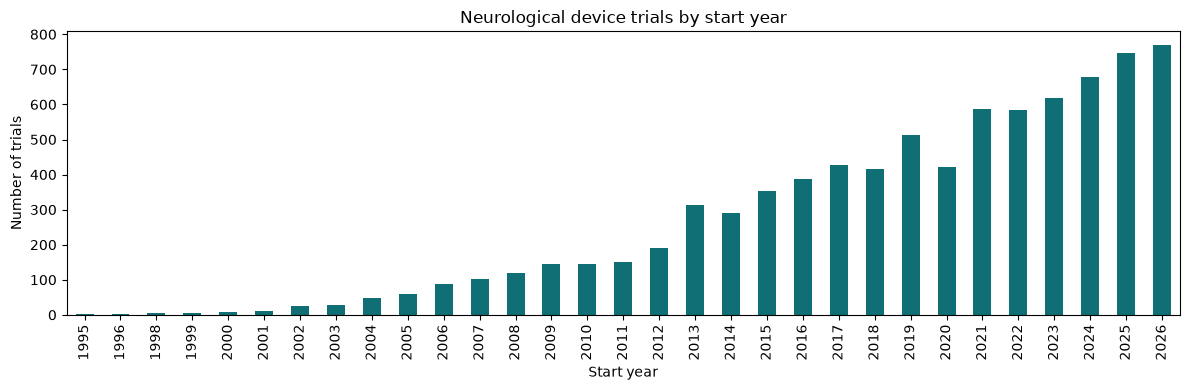

In [7]:
trials["start_year"] = pd.to_numeric(trials["start_date"].str[:4], errors="coerce")
counts = trials["start_year"].value_counts().sort_index().loc[1995:2026]
counts.index = counts.index.astype(int)

ax = counts.plot(kind="bar", figsize=(12, 4), color="#0f6f74")
ax.set_xlabel("Start year")
ax.set_ylabel("Number of trials")
ax.set_title("Neurological device trials by start year")
plt.tight_layout()
plt.savefig("../reports/figures/trials_by_start_year.png", dpi=150)

In [8]:
bci = "synchron|neuralink|precision neuro|paradromics|blackrock"
mask = (
    trials["lead_sponsor"].str.contains(bci, case=False, na=False)
    | trials["title"].str.contains(bci, case=False, na=False)
    | trials["device_names"].str.contains(bci, case=False, na=False)
)
trials.loc[mask, ["nct_id", "lead_sponsor", "title", "overall_status", "start_date"]]

,nct_id,lead_sponsor,title,overall_status,start_date
65,NCT04710004,Emory University,Electrophysiological Biomarkers in MTLE Patients.,TERMINATED,2021-11-30
335,NCT07139093,Universitätsklinikum Hamburg-Eppendorf,Testing of an Interface for Synchronizing tACS...,COMPLETED,2025-09-30
2204,NCT04606095,University of Michigan,Explosive Synchronization of Brain Network Act...,ACTIVE_NOT_RECRUITING,2020-11-13
2570,NCT01683019,Wave Neuroscience,Feasibility Study to Test Clinical Efficacy of...,COMPLETED,2008-06
2591,NCT02839798,Butler Hospital,NeoSync TMS Treatment for Bipolar I Depression,TERMINATED,2016-05
2612,NCT03282136,University of Campania Luigi Vanvitelli,SGLT2i and Incretin and CRTd.,COMPLETED,2017-09-01
2615,NCT02981381,Providence VA Medical Center,Synchronized Transcranial Magnetic Stimulation...,COMPLETED,2016-10-13
2625,NCT04575675,Cheng-Hsin General Hospital,Dapagliflozin on Hypotensive Heart Failure Pat...,COMPLETED,2020-05-29
2665,NCT03421808,Medical University of South Carolina,EEG Synchronized TMS Trial for Depression,COMPLETED,2018-11-30
2708,NCT02920840,University Hospital Tuebingen,Brain-oscillation Synchronised Stimulation of ...,COMPLETED,2016-09


In [9]:
bci = r"\bsynchron\b|neuralink|paradromics|precision neuro|blackrock|braingate|brain[- ]computer interface"
mask = (
    trials["lead_sponsor"].str.contains(bci, case=False, na=False)
    | trials["title"].str.contains(bci, case=False, na=False)
    | trials["device_names"].str.contains(bci, case=False, na=False)
)
trials.loc[mask, ["nct_id", "lead_sponsor", "title", "overall_status", "start_date"]]

,nct_id,lead_sponsor,title,overall_status,start_date
320,NCT06690931,g.tec medical engineering GmbH,Neurofeedback Rehabilitation With FES and VR f...,COMPLETED,2024-12-09
1027,NCT07214974,"Noah Tech, Corp.",Mild Cognitive Impairment Community Screening ...,NOT_YET_RECRUITING,2026-09-01
2227,NCT03032497,Tan Tock Seng Hospital,Brain-Computer Interface (BCI)-Based Feedback ...,COMPLETED,2017-06-05
2912,NCT03696667,"Institute of Mental Health, Singapore",Affect Regulation Based on Brain-computer Inte...,COMPLETED,2018-03-08
3429,NCT07783906,Shanghai Mental Health Center,Precision Closed-loop Brain-Computer Interface...,NOT_YET_RECRUITING,2026-08
...,...,...,...,...,...
8218,NCT01123148,University of Michigan,A P300 Brain Computer Interface to Operate Pow...,COMPLETED,2010-01
8227,NCT01123200,University of Michigan,An In-home Study of Brain Computer Interfaces,COMPLETED,2010-01
8237,NCT03900247,University of Aarhus,Restore Motor Function Through Robotic Arm Exo...,UNKNOWN,2019-03-18
8243,NCT07533903,"Synchron, Inc.",Functional Outcomes and Control Using Synchron...,RECRUITING,2026-05-22


In [10]:
bci_trials = trials[mask]
print(len(bci_trials), "BCI-related trials")
display(bci_trials["sponsor_class"].value_counts())
display(bci_trials["lead_sponsor"].value_counts().head(15))

bci_trials.to_csv("../data/processed/bci_trials.csv", index=False)

66 BCI-related trials


sponsor_class
OTHER        44
INDUSTRY     17
OTHER_GOV     5
Name: count, dtype: int64

lead_sponsor
Neuralink Corp                             6
Tan Tock Seng Hospital                     4
Leigh R. Hochberg, MD, PhD.                4
University of Michigan                     4
Instituto Nacional de Rehabilitacion       3
National University Hospital, Singapore    2
Beijing Tiantan Hospital                   2
University of Calgary                      2
Synchron Medical, Inc.                     2
Aristotle University Of Thessaloniki       2
University Hospital, Grenoble              2
The Hong Kong Polytechnic University       2
University of Aarhus                       2
Synchron, Inc.                             2
g.tec medical engineering GmbH             1
Name: count, dtype: int64